# GB-7 — PSO-Based Hyperparameter Optimization of YOLOv8n

This notebook extracts the **final PSO Experiment 2** from the original `PSO Project.ipynb`. The original code, execution counts, and saved outputs are preserved. **Do not use Run All:** the cells perform GPU training and may create or overwrite experiment artifacts. The dataset path is specific to the original Windows machine.

**Experiment:** 5 particles, 5 iterations, 10 epochs per particle evaluation; fitness = validation mAP@50–95; final selected configuration retrained for 50 epochs.


## 1. PSO search and optimization history

Original source: code cell 37. This cell defines its own dataset path, search configuration, optimization loop, and result saving. The existing outputs document the completed run.


Starting NEW PSO experiment
Particles: 5
Iterations: 5
Epochs per particle: 10
Output folder: C:\Users\pc\BDFD9 Bangladesh Centric Fabric Defect Dataset\extracted\YOLO_Experiments\PSO_Experiment_2_5P_5I_10E

############################################################
PSO ITERATION 1/5
############################################################

Iteration 1 | Particle 1
Parameters: {'lr0': 0.00353111691382141, 'momentum': 0.8789981191553694, 'weight_decay': 0.0014011828071430314}
Ultralytics 8.4.208  Python-3.10.20 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3090, 24576MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\pc\BDFD9 Bangladesh Centric Fabric Defect Dataset\extracted\BDFD9_YOLO\data.y

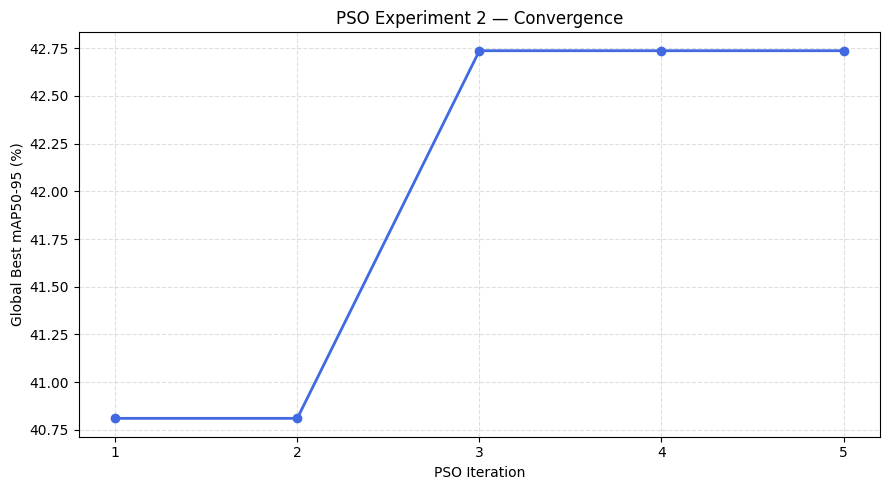

Graph saved: C:\Users\pc\BDFD9 Bangladesh Centric Fabric Defect Dataset\extracted\YOLO_Experiments\PSO_Experiment_2_5P_5I_10E\PSO_Convergence_Experiment_2.png

PSO Experiment 2 completed successfully!


In [44]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import gc
import torch
from ultralytics import YOLO

# ============================================================
# 1. CONFIGURATION
# ============================================================

dataset_yaml = Path(
    r"C:\Users\pc\BDFD9 Bangladesh Centric Fabric Defect Dataset"
    r"\extracted\BDFD9_YOLO\data.yaml"
)

experiments_root = dataset_yaml.parent.parent / "YOLO_Experiments"

# Separate folder to avoid conflicts with earlier experiments
pso_dir = experiments_root / "PSO_Experiment_2_5P_5I_10E"
pso_dir.mkdir(parents=True, exist_ok=True)

assert dataset_yaml.exists(), f"Dataset not found: {dataset_yaml}"

NUM_PARTICLES = 5
NUM_ITERATIONS = 5
PSO_EPOCHS = 10

W = 0.6
C1 = 1.5
C2 = 1.5
SEED = 42

lower_bounds = np.array([-4.0, 0.80, -5.0])
upper_bounds = np.array([-2.0, 0.98, -2.5])

max_velocity = 0.2 * (upper_bounds - lower_bounds)

rng = np.random.default_rng(SEED)

state_file = pso_dir / "pso_state.json"
history_file = pso_dir / "fitness_history.csv"
summary_file = pso_dir / "final_pso_results.json"

def decode_particle(position):
    return {
        "lr0": float(10 ** position[0]),
        "momentum": float(position[1]),
        "weight_decay": float(10 ** position[2])
    }

# ============================================================
# 2. SAVE / RESUME STATE
# ============================================================

def save_state(next_iteration, next_particle):
    state = {
        "next_iteration": next_iteration,
        "next_particle": next_particle,
        "positions": positions.tolist(),
        "velocities": velocities.tolist(),
        "pbest_positions": pbest_positions.tolist(),
        "pbest_fitness": pbest_fitness.tolist(),
        "gbest_position": (
            None if gbest_position is None
            else gbest_position.tolist()
        ),
        "gbest_fitness": float(gbest_fitness),
        "rng_state": rng.bit_generator.state,
        "config": {
            "particles": NUM_PARTICLES,
            "iterations": NUM_ITERATIONS,
            "epochs": PSO_EPOCHS,
            "seed": SEED,
            "lower_bounds": lower_bounds.tolist(),
            "upper_bounds": upper_bounds.tolist()
        }
    }

    temp_file = state_file.with_suffix(".tmp")

    with open(temp_file, "w", encoding="utf-8") as f:
        json.dump(state, f, indent=2)

    temp_file.replace(state_file)

if state_file.exists():
    with open(state_file, "r", encoding="utf-8") as f:
        saved = json.load(f)

    config = saved["config"]

    assert config["particles"] == NUM_PARTICLES
    assert config["iterations"] == NUM_ITERATIONS
    assert config["epochs"] == PSO_EPOCHS
    assert config["seed"] == SEED
    assert np.allclose(config["lower_bounds"], lower_bounds)
    assert np.allclose(config["upper_bounds"], upper_bounds)

    positions = np.array(saved["positions"], dtype=float)
    velocities = np.array(saved["velocities"], dtype=float)
    pbest_positions = np.array(saved["pbest_positions"], dtype=float)
    pbest_fitness = np.array(saved["pbest_fitness"], dtype=float)

    gbest_position = (
        None if saved["gbest_position"] is None
        else np.array(saved["gbest_position"], dtype=float)
    )

    gbest_fitness = float(saved["gbest_fitness"])
    start_iteration = saved["next_iteration"]
    start_particle = saved["next_particle"]

    rng.bit_generator.state = saved["rng_state"]

    print("Resuming existing PSO experiment")

else:
    positions = rng.uniform(
        lower_bounds,
        upper_bounds,
        size=(NUM_PARTICLES, 3)
    )

    velocities = np.zeros_like(positions)
    pbest_positions = positions.copy()
    pbest_fitness = np.full(NUM_PARTICLES, -np.inf)

    gbest_position = None
    gbest_fitness = -np.inf

    start_iteration = 1
    start_particle = 0

    print("Starting NEW PSO experiment")

print(f"Particles: {NUM_PARTICLES}")
print(f"Iterations: {NUM_ITERATIONS}")
print(f"Epochs per particle: {PSO_EPOCHS}")
print(f"Output folder: {pso_dir}")

# ============================================================
# 3. FITNESS HISTORY
# ============================================================

history = []

if history_file.exists():
    history = pd.read_csv(history_file).to_dict("records")

def save_history():
    pd.DataFrame(history).to_csv(history_file, index=False)

def find_existing_fitness(position):
    params = decode_particle(position)

    for record in history:
        if (
            np.isclose(record["lr0"], params["lr0"], rtol=1e-10)
            and np.isclose(
                record["momentum"], params["momentum"],
                rtol=1e-10, atol=1e-12
            )
            and np.isclose(
                record["weight_decay"], params["weight_decay"],
                rtol=1e-10, atol=1e-12
            )
        ):
            return float(record["fitness"])

    return None

# ============================================================
# 4. FITNESS FUNCTION
# ============================================================

def evaluate_particle(position, particle_id, iteration):

    params = decode_particle(position)

    cached = find_existing_fitness(position)

    if cached is not None:
        print(f"Reusing previous fitness: {cached:.5f}")
        return cached

    run_name = f"iter_{iteration:02d}_particle_{particle_id:02d}"
    run_dir = pso_dir / run_name
    best_path = run_dir / "weights" / "best.pt"

    print(f"\n{'=' * 55}")
    print(f"Iteration {iteration} | Particle {particle_id}")
    print("Parameters:", params)
    print(f"{'=' * 55}")

    if not best_path.exists():

        if run_dir.exists():
            raise RuntimeError(
                f"Incomplete training folder: {run_dir}\n"
                "Inspect this folder before restarting."
            )

        model = YOLO("yolov8n.pt")

        model.train(
            data=str(dataset_yaml.resolve()),
            epochs=PSO_EPOCHS,
            imgsz=640,
            batch=16,
            device=0,
            workers=0,
            seed=SEED,
            deterministic=True,
            optimizer="AdamW",
            lr0=params["lr0"],
            momentum=params["momentum"],
            weight_decay=params["weight_decay"],
            patience=PSO_EPOCHS,
            close_mosaic=0,
            amp=True,
            project=str(pso_dir.resolve()),
            name=run_name,
            exist_ok=False,
            plots=False,
            verbose=False
        )

        del model
        gc.collect()
        torch.cuda.empty_cache()

    if not best_path.exists():
        raise FileNotFoundError(best_path)

    best_model = YOLO(str(best_path))

    metrics = best_model.val(
        data=str(dataset_yaml.resolve()),
        split="val",
        imgsz=640,
        batch=16,
        device=0,
        workers=0,
        plots=False,
        verbose=False
    )

    fitness = float(metrics.box.map)

    record = {
        "iteration": iteration,
        "particle": particle_id,
        "lr0": params["lr0"],
        "momentum": params["momentum"],
        "weight_decay": params["weight_decay"],
        "fitness": fitness,
        "mAP50": float(metrics.box.map50),
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "checkpoint": str(best_path)
    }

    history.append(record)
    save_history()

    print(f"Fitness mAP50-95: {fitness:.5f}")
    print(f"mAP50: {metrics.box.map50:.5f}")

    del best_model, metrics
    gc.collect()
    torch.cuda.empty_cache()

    return fitness

# ============================================================
# 5. PSO MAIN LOOP
# ============================================================

for iteration in range(start_iteration, NUM_ITERATIONS + 1):

    print(f"\n{'#' * 60}")
    print(f"PSO ITERATION {iteration}/{NUM_ITERATIONS}")
    print(f"{'#' * 60}")

    first_particle = (
        start_particle if iteration == start_iteration else 0
    )

    for i in range(first_particle, NUM_PARTICLES):

        fitness = evaluate_particle(
            positions[i],
            particle_id=i + 1,
            iteration=iteration
        )

        if fitness > pbest_fitness[i]:
            pbest_fitness[i] = fitness
            pbest_positions[i] = positions[i].copy()

        if fitness > gbest_fitness:
            gbest_fitness = fitness
            gbest_position = positions[i].copy()

            print("\nNEW GLOBAL BEST!")
            print("Fitness:", gbest_fitness)
            print("Parameters:", decode_particle(gbest_position))

        save_state(iteration, i + 1)

    print(f"\nIteration {iteration} completed")
    print(f"Global best: {gbest_fitness:.5f}")

    if iteration == NUM_ITERATIONS:
        save_state(NUM_ITERATIONS + 1, 0)
        break

    # Velocity and position updates
    for i in range(NUM_PARTICLES):

        r1 = rng.random(3)
        r2 = rng.random(3)

        cognitive = (
            C1 * r1 * (pbest_positions[i] - positions[i])
        )

        social = (
            C2 * r2 * (gbest_position - positions[i])
        )

        velocities[i] = (
            W * velocities[i] + cognitive + social
        )

        velocities[i] = np.clip(
            velocities[i],
            -max_velocity,
            max_velocity
        )

        positions[i] = np.clip(
            positions[i] + velocities[i],
            lower_bounds,
            upper_bounds
        )

    save_state(iteration + 1, 0)

# ============================================================
# 6. FINAL RESULTS
# ============================================================

best_params = decode_particle(gbest_position)

final_results = {
    "model": "YOLOv8n",
    "optimization": "PSO Experiment 2 (5P, 5I, 10E)",
    "particles": NUM_PARTICLES,
    "iterations": NUM_ITERATIONS,
    "epochs_per_evaluation": PSO_EPOCHS,
    "fitness_metric": "Validation mAP50-95",
    "best_fitness": float(gbest_fitness),
    "best_hyperparameters": best_params,
    "total_unique_evaluations": len(history)
}

with open(summary_file, "w", encoding="utf-8") as f:
    json.dump(final_results, f, indent=4)

print("\n===== FINAL PSO RESULTS =====")
print("Best fitness:", gbest_fitness)
print("Best hyperparameters:", best_params)
print("Unique evaluations:", len(history))

# ============================================================
# 7. CONVERGENCE GRAPH
# ============================================================

df = pd.DataFrame(history)

if not df.empty:

    convergence = (
        df.groupby("iteration")["fitness"]
        .max()
        .reindex(range(1, NUM_ITERATIONS + 1))
        .cummax()
        .ffill()
    )

    plt.figure(figsize=(9, 5))

    plt.plot(
        convergence.index,
        convergence.values * 100,
        marker="o",
        linewidth=2,
        color="royalblue"
    )

    plt.xlabel("PSO Iteration")
    plt.ylabel("Global Best mAP50-95 (%)")
    plt.title("PSO Experiment 2 — Convergence")

    plt.xticks(range(1, NUM_ITERATIONS + 1))
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()

    graph_path = pso_dir / "PSO_Convergence_Experiment_2.png"

    plt.savefig(graph_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Graph saved:", graph_path)

print("\nPSO Experiment 2 completed successfully!")


## 2. Final 50-epoch PSO-optimized training

Original source: code cell 38. This cell loads `final_pso_results.json` from the completed search and trains the selected model. **Executing this cell starts training again.** Its saved output is retained for documentation.


In [45]:

from pathlib import Path
from ultralytics import YOLO
import json

experiments_root = dataset_yaml.parent.parent / "YOLO_Experiments"

pso_dir = experiments_root / "PSO_Experiment_2_5P_5I_10E"

with open(pso_dir / "final_pso_results.json", "r") as f:
    pso_results = json.load(f)

best_params = pso_results["best_hyperparameters"]

print("Selected PSO hyperparameters:", best_params)

model = YOLO("yolov8n.pt")

model.train(
    data=str(dataset_yaml.resolve()),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=0,
    seed=42,
    deterministic=True,
    optimizer="AdamW",
    lr0=best_params["lr0"],
    momentum=best_params["momentum"],
    weight_decay=best_params["weight_decay"],
    patience=50,
    close_mosaic=10,
    amp=True,
    project=str(experiments_root.resolve()),
    name="YOLOv8n_PSO_Experiment_2_50_Epochs",
    exist_ok=False,
    plots=True
)

print("\nTraining completed!")
print("Saved model directory:", model.trainer.save_dir)
print("Best model:", Path(model.trainer.save_dir) / "weights" / "best.pt")


Selected PSO hyperparameters: {'lr0': 0.0005596443158499851, 'momentum': 0.8602855265995631, 'weight_decay': 0.0028154436412772326}
Ultralytics 8.4.208  Python-3.10.20 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3090, 24576MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\pc\BDFD9 Bangladesh Centric Fabric Defect Dataset\extracted\BDFD9_YOLO\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_wid

## Notes

- Baseline model training and dataset preparation are documented separately under GB-1 and GB-6.
- Test-set comparison, deployment model copying, and comparison visualizations remain outside this PSO-focused notebook and can be documented in the separate comparison task.
- The notebook does not include external artifacts such as `fitness_history.csv`, `final_pso_results.json`, training graphs, or `.pt` weights. Those should be copied from the original experiment directories separately.
